## 1. Install and import libraries

In [1]:
!pip -q install wfdb numpy pandas scipy matplotlib seaborn scikit-learn tensorflow

import os
import gc
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
import tensorflow as tf

from scipy.signal import butter, sosfiltfilt
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Libraries imported successfully!


## 2. Download the MIT-BIH Arrhythmia Database

In [2]:
DATA_DIR = "/content/mitdb"
os.makedirs(DATA_DIR, exist_ok=True)

print("Downloading MIT-BIH Arrhythmia Database...")
wfdb.dl_database("mitdb", dl_dir=DATA_DIR)

record_files = sorted(
    f.replace(".hea", "")
    for f in os.listdir(DATA_DIR)
    if f.endswith(".hea")
)

print("Total recordings downloaded:", len(record_files))
print("Available recordings:", record_files)

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

## 3. Define AAMI classes and patient-level record split


In [3]:
AAMI_MAPPING = {
    # N: normal and bundle branch block beats
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",

    # S: supraventricular ectopic beats
    "A": "S", "a": "S", "J": "S", "S": "S",

    # V: ventricular ectopic beats
    "V": "V", "E": "V",

    # F: fusion beats
    "F": "F",

    # Q: unknown / paced-related beat categories
    "/": "Q", "f": "Q", "Q": "Q"
}

CLASS_NAMES = ["N", "S", "V", "F", "Q"]
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

DS1_RECORDS = [
    "101", "106", "108", "109", "112", "114", "115", "116",
    "118", "119", "122", "124", "201", "203", "205", "207",
    "208", "209", "215", "220", "223", "230"
]

DS2_RECORDS = [
    "100", "103", "105", "111", "113", "117", "121", "123",
    "200", "202", "210", "212", "213", "214", "219", "221",
    "222", "228", "231", "232", "233", "234"
]

PACED_RECORDS = {"102", "104", "107", "217"}

VAL_RECORDS = ["106", "114", "124", "203"]
TRAIN_RECORDS = [r for r in DS1_RECORDS if r not in VAL_RECORDS]
TEST_RECORDS = DS2_RECORDS.copy()

assert not (set(TRAIN_RECORDS) & set(VAL_RECORDS))
assert not (set(TRAIN_RECORDS) & set(TEST_RECORDS))
assert not (set(VAL_RECORDS) & set(TEST_RECORDS))

print("Training records:", len(TRAIN_RECORDS), TRAIN_RECORDS)
print("Validation records:", len(VAL_RECORDS), VAL_RECORDS)
print("Testing records:", len(TEST_RECORDS), TEST_RECORDS)
print("Patient/record-level separation verified.")

Training records: 18 ['101', '108', '109', '112', '115', '116', '118', '119', '122', '201', '205', '207', '208', '209', '215', '220', '223', '230']
Validation records: 4 ['106', '114', '124', '203']
Testing records: 22 ['100', '103', '105', '111', '113', '117', '121', '123', '200', '202', '210', '212', '213', '214', '219', '221', '222', '228', '231', '232', '233', '234']
Patient/record-level separation verified.


## 4. Inspect a raw ECG recording

Record: 100
Sampling frequency: 360 Hz
Signal shape: (650000, 2)
Signal channels: ['MLII', 'V5']


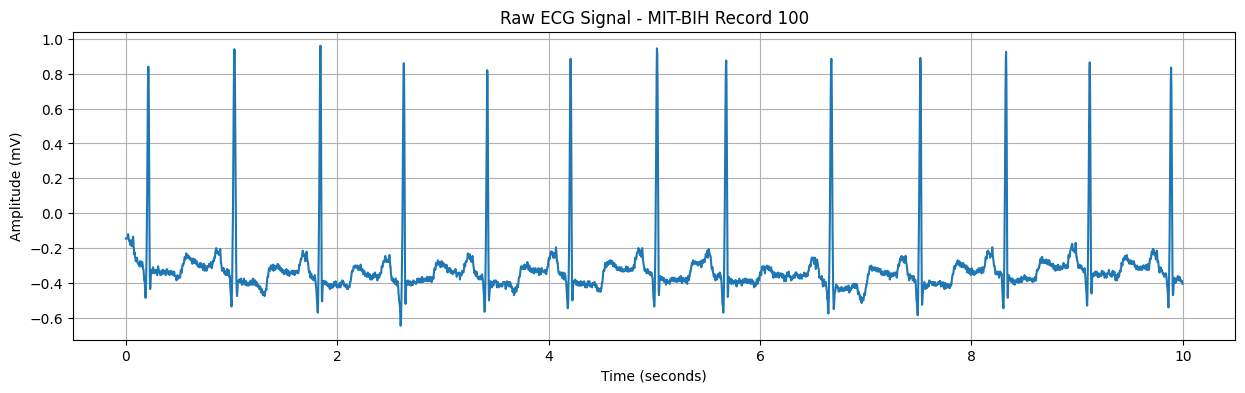

In [4]:
record_name = "100"
record = wfdb.rdrecord(os.path.join(DATA_DIR, record_name))

signal = record.p_signal
fs = record.fs

print("Record:", record_name)
print("Sampling frequency:", fs, "Hz")
print("Signal shape:", signal.shape)
print("Signal channels:", record.sig_name)

channel = record.sig_name.index("MLII") if "MLII" in record.sig_name else 0
ecg_signal = signal[:, channel]

duration = 10
samples = int(duration * fs)
time_axis = np.arange(samples) / fs

plt.figure(figsize=(15, 4))
plt.plot(time_axis, ecg_signal[:samples])
plt.title(f"Raw ECG Signal - MIT-BIH Record {record_name}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.show()

## 5. Filter ECG signal (0.5–40 Hz)

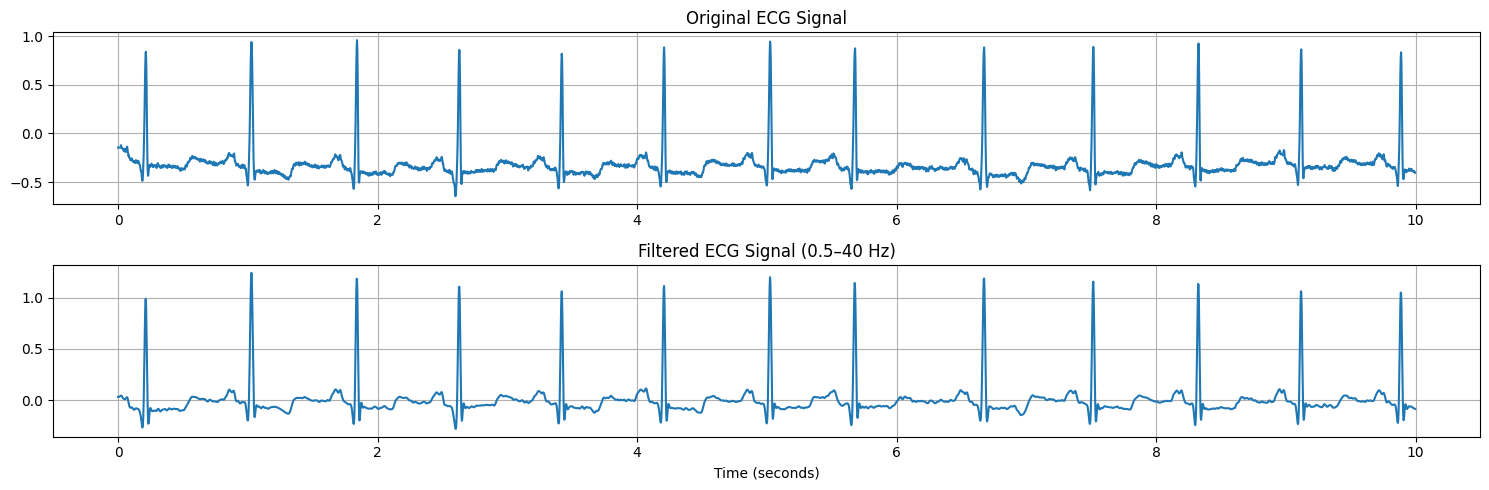

ECG filtering completed.


In [5]:
def filter_ecg(signal, fs=360):
    sos = butter(
        4, [0.5, 40.0],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, signal)

filtered_signal = filter_ecg(ecg_signal, fs)

plt.figure(figsize=(15, 5))
plt.subplot(2, 1, 1)
plt.plot(time_axis, ecg_signal[:samples])
plt.title("Original ECG Signal")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(time_axis, filtered_signal[:samples])
plt.title("Filtered ECG Signal (0.5–40 Hz)")
plt.xlabel("Time (seconds)")
plt.grid(True)

plt.tight_layout()
plt.show()
print("ECG filtering completed.")

## 6. Segment beats around annotated R-peaks



Extracted beats: (2271, 256)
Labels: (2271,)


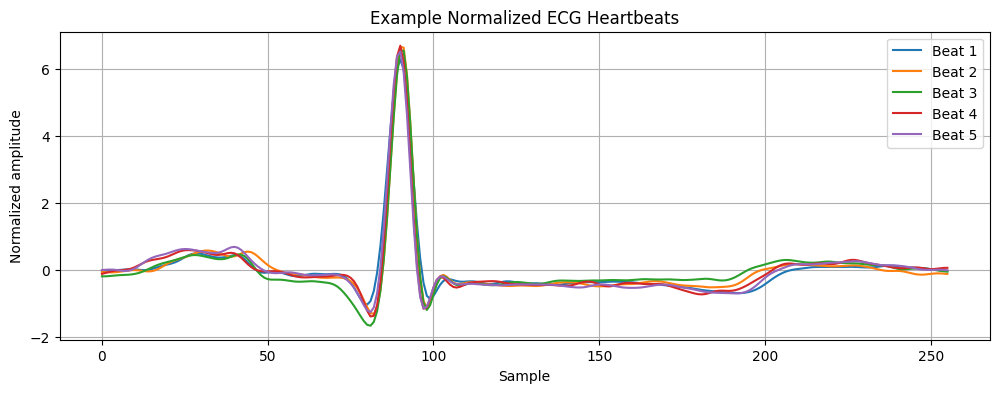

In [6]:
BEAT_LENGTH = 256
BEFORE_R = 90
AFTER_R = BEAT_LENGTH - BEFORE_R

def normalize_beat(beat):
    mean = np.mean(beat)
    std = np.std(beat)
    if std < 1e-8:
        return np.zeros_like(beat)
    return (beat - mean) / std

def extract_beats(record_id):
    record_path = os.path.join(DATA_DIR, record_id)
    record = wfdb.rdrecord(record_path)

    fs = record.fs
    if fs != 360:
        raise ValueError(f"Unexpected sampling frequency in {record_id}: {fs}")

    channel = record.sig_name.index("MLII") if "MLII" in record.sig_name else 0
    signal = record.p_signal[:, channel]
    signal = filter_ecg(signal, fs)

    annotation = wfdb.rdann(record_path, "atr")

    beats, labels = [], []

    for sample, symbol in zip(annotation.sample, annotation.symbol):
        if symbol not in AAMI_MAPPING:
            continue

        start = sample - BEFORE_R
        end = sample + AFTER_R

        if start < 0 or end > len(signal):
            continue

        beat = signal[start:end]
        if len(beat) != BEAT_LENGTH:
            continue

        beats.append(normalize_beat(beat))
        labels.append(CLASS_TO_INDEX[AAMI_MAPPING[symbol]])

    if not beats:
        return np.empty((0, BEAT_LENGTH), dtype=np.float32), np.empty((0,), dtype=np.int64)

    return np.asarray(beats, dtype=np.float32), np.asarray(labels, dtype=np.int64)

sample_beats, sample_labels = extract_beats("100")
print("Extracted beats:", sample_beats.shape)
print("Labels:", sample_labels.shape)

plt.figure(figsize=(12, 4))
for i in range(min(5, len(sample_beats))):
    plt.plot(sample_beats[i], label=f"Beat {i+1}")
plt.title("Example Normalized ECG Heartbeats")
plt.xlabel("Sample")
plt.ylabel("Normalized amplitude")
plt.legend()
plt.grid(True)
plt.show()

## 7. Build train, validation and test datasets

In [7]:
def build_dataset(record_list, dataset_name):
    all_beats, all_labels = [], []
    print(f"\nProcessing {dataset_name}...")

    for record_id in record_list:
        try:
            X, y = extract_beats(record_id)
            all_beats.append(X)
            all_labels.append(y)
            print(f"Record {record_id}: {len(X)} beats extracted")
        except Exception as e:
            print(f"Error processing record {record_id}: {e}")

    if not all_beats:
        raise RuntimeError(f"No recordings were successfully processed for {dataset_name}.")

    X = np.concatenate(all_beats, axis=0)
    y = np.concatenate(all_labels, axis=0)

    if len(y) == 0:
        raise RuntimeError(f"No eligible annotated beats found for {dataset_name}.")

    print(f"{dataset_name} shape:", X.shape)
    print(f"{dataset_name} labels:", y.shape)
    return X, y

X_train, y_train = build_dataset(TRAIN_RECORDS, "Training Dataset")
X_val, y_val = build_dataset(VAL_RECORDS, "Validation Dataset")
X_test, y_test = build_dataset(TEST_RECORDS, "Testing Dataset")

print("\nFinal dataset shapes:")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Processing Training Dataset...
Record 101: 1864 beats extracted
Record 108: 1762 beats extracted
Record 109: 2531 beats extracted
Record 112: 2538 beats extracted
Record 115: 1952 beats extracted
Record 116: 2411 beats extracted
Record 118: 2277 beats extracted
Record 119: 1987 beats extracted
Record 122: 2475 beats extracted
Record 201: 1963 beats extracted
Record 205: 2655 beats extracted
Record 207: 1859 beats extracted
Record 208: 2953 beats extracted
Record 209: 3004 beats extracted
Record 215: 3362 beats extracted
Record 220: 2046 beats extracted
Record 223: 2604 beats extracted
Record 230: 2255 beats extracted
Training Dataset shape: (42498, 256)
Training Dataset labels: (42498,)

Processing Validation Dataset...
Record 106: 2027 beats extracted
Record 114: 1879 beats extracted
Record 124: 1618 beats extracted
Record 203: 2980 beats extracted
Validation Dataset shape: (8504, 256)
Validation Dataset labels: (8504,)

Processing Testing Dataset...
Record 100: 2271 beats extracted


## 8. Explore AAMI class distribution


Training Class Distribution


,Class,Count
0,N,38457
1,S,899
2,V,2734
3,F,404
4,Q,4


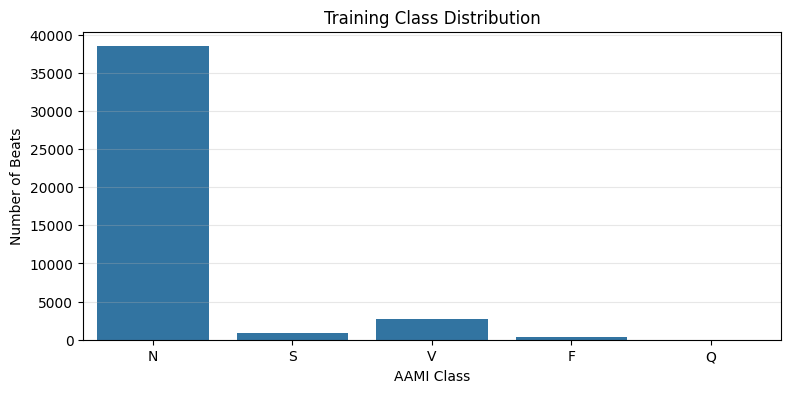


Validation Class Distribution


,Class,Count
0,N,7391
1,S,45
2,V,1054
3,F,10
4,Q,4


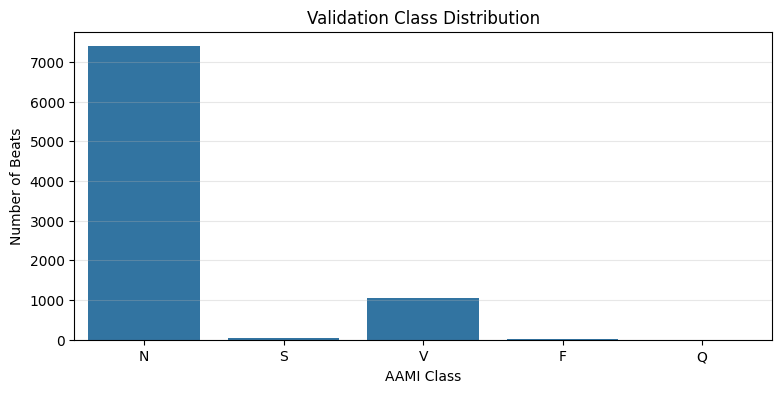


Testing Class Distribution


,Class,Count
0,N,44240
1,S,1837
2,V,3220
3,F,388
4,Q,7


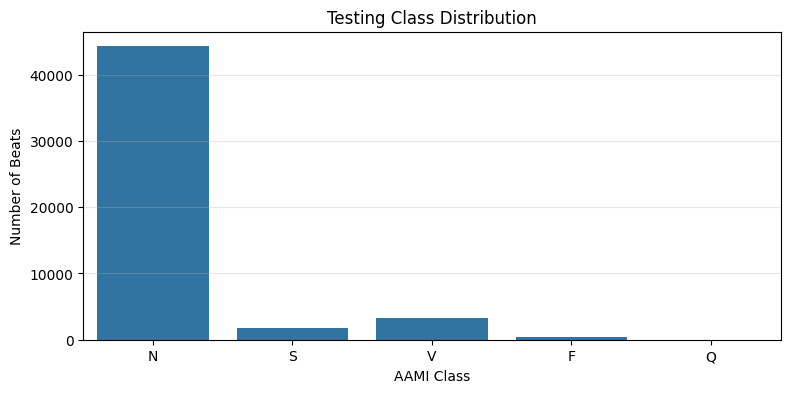

In [8]:
def show_distribution(y, title):
    counts = pd.Series(y).value_counts().reindex(range(5), fill_value=0)
    distribution = pd.DataFrame({
        "Class": CLASS_NAMES,
        "Count": counts.values
    })

    print("\n" + title)
    display(distribution)

    plt.figure(figsize=(9, 4))
    sns.barplot(data=distribution, x="Class", y="Count")
    plt.title(title)
    plt.xlabel("AAMI Class")
    plt.ylabel("Number of Beats")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

show_distribution(y_train, "Training Class Distribution")
show_distribution(y_val, "Validation Class Distribution")
show_distribution(y_test, "Testing Class Distribution")

## 9. Prepare recurrent model inputs and class weights

In [9]:
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

CLASS_WEIGHTS = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("\nClass weights:")
for cls, weight in CLASS_WEIGHTS.items():
    print(CLASS_NAMES[cls], ":", round(weight, 4))

Training shape: (42498, 256, 1)
Validation shape: (8504, 256, 1)
Testing shape: (49692, 256, 1)

Class weights:
N : 0.221
S : 9.4545
V : 3.1089
F : 21.0386
Q : 2124.9


## 10. Build comparable RNN, LSTM and GRU models

In [10]:
def build_model(model_type):
    model = Sequential()
    model.add(Input(shape=(BEAT_LENGTH, 1)))

    if model_type == "RNN":
        model.add(SimpleRNN(64, activation="tanh"))
    elif model_type == "LSTM":
        model.add(LSTM(64, activation="tanh"))
    elif model_type == "GRU":
        model.add(GRU(64, activation="tanh"))
    else:
        raise ValueError("model_type must be RNN, LSTM or GRU")

    model.add(Dropout(0.3))
    model.add(Dense(32, activation="relu"))
    model.add(Dense(5, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

for model_name in ["RNN", "LSTM", "GRU"]:
    print("\n" + "=" * 50)
    print(model_name, "MODEL")
    print("=" * 50)
    model = build_model(model_name)
    model.summary()
    del model
    gc.collect()


RNN MODEL


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,469 (25.27 KB)

 Trainable params: 6,469 (25.27 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,109 (59.02 KB)

 Trainable params: 15,109 (59.02 KB)

 Non-trainable params: 0 (0.00 B)

## 11. Train all three models

In [11]:
EPOCHS = 30
BATCH_SIZE = 256

def train_model(model_name):
    print("\n" + "=" * 60)
    print("TRAINING", model_name)
    print("=" * 60)

    model = build_model(model_name)

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1
        )
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHTS,
        callbacks=callbacks,
        verbose=1
    )

    print(model_name, "training completed.")
    return model, history

models = {}
histories = {}

for model_name in ["RNN", "LSTM", "GRU"]:
    model, history = train_model(model_name)
    models[model_name] = model
    histories[model_name] = history

print("All three models trained.")


TRAINING RNN
Epoch 1/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 13s 49ms/step - accuracy: 0.2950 - loss: 1.5159 - val_accuracy: 0.6766 - val_loss: 1.1919 - learning_rate: 0.0010
Epoch 2/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.1415 - loss: 1.4142 - val_accuracy: 0.0597 - val_loss: 1.4830 - learning_rate: 0.0010
Epoch 3/30
166/167 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3661 - loss: 2.1095
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
167/167 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.3685 - loss: 1.5017 - val_accuracy: 0.6251 - val_loss: 1.3399 - learning_rate: 0.0010
Epoch 4/30
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.4763 - loss: 1.3138 - val_accuracy: 0.6610 - val_loss: 1.3082 - learning_rate: 5.0000e-04
Epoch 5/30
166/167 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4296 - loss: 1.6871
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
167/167 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 

## 12. Plot training accuracy and validation loss

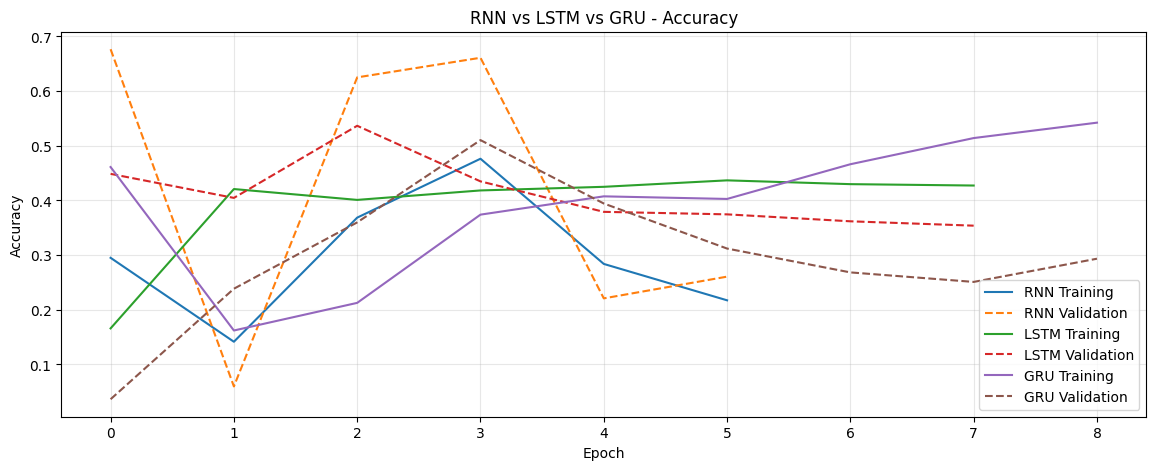

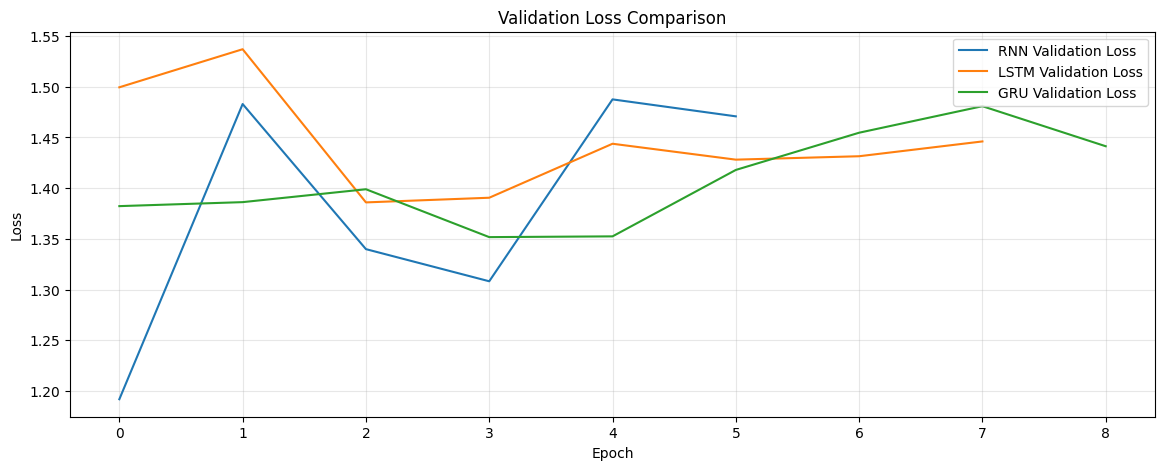

In [12]:
plt.figure(figsize=(14, 5))
for name, history in histories.items():
    plt.plot(history.history["accuracy"], label=f"{name} Training")
    plt.plot(history.history["val_accuracy"], linestyle="--", label=f"{name} Validation")
plt.title("RNN vs LSTM vs GRU - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(14, 5))
for name, history in histories.items():
    plt.plot(history.history["val_loss"], label=f"{name} Validation Loss")
plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 13. Evaluate models on the independent test set

In [13]:
results = []
predictions = {}

for name, model in models.items():
    print("\n" + "=" * 60)
    print("EVALUATING:", name)
    print("=" * 60)

    probabilities = model.predict(X_test, batch_size=BATCH_SIZE, verbose=1)
    y_pred = np.argmax(probabilities, axis=1)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Precision (Weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (Weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1 (Weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

    print("\nClassification Report:\n")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=CLASS_NAMES,
        zero_division=0
    ))

results_df = pd.DataFrame(results)
print("\nFINAL MODEL COMPARISON")
display(results_df.style.format({
    col: "{:.4f}" for col in results_df.columns if col != "Model"
}))


EVALUATING: RNN
195/195 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step

Classification Report:

              precision    recall  f1-score   support

           N       0.86      0.66      0.75     44240
           S       0.05      0.32      0.09      1837
           V       0.01      0.00      0.00      3220
           F       0.00      0.02      0.00       388
           Q       0.00      0.00      0.00         7

    accuracy                           0.60     49692
   macro avg       0.19      0.20      0.17     49692
weighted avg       0.77      0.60      0.67     49692


EVALUATING: LSTM
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Classification Report:

              precision    recall  f1-score   support

           N       0.89      0.35      0.51     44240
           S       0.03      0.18      0.05      1837
           V       0.16      0.62      0.25      3220
           F       0.00      0.01      0.00       388
           Q       0.00      0.14      0.00         7

    accuracy      

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),Precision (Weighted),Recall (Weighted),F1 (Weighted)
0,RNN,0.6021,0.1860,0.2007,0.1680,0.7723,0.6021,0.6712
1,LSTM,0.3622,0.2157,0.2619,0.1627,0.8023,0.3622,0.4690
2,GRU,0.3282,0.2035,0.2219,0.1442,0.7770,0.3282,0.4267


## 14. Confusion matrices

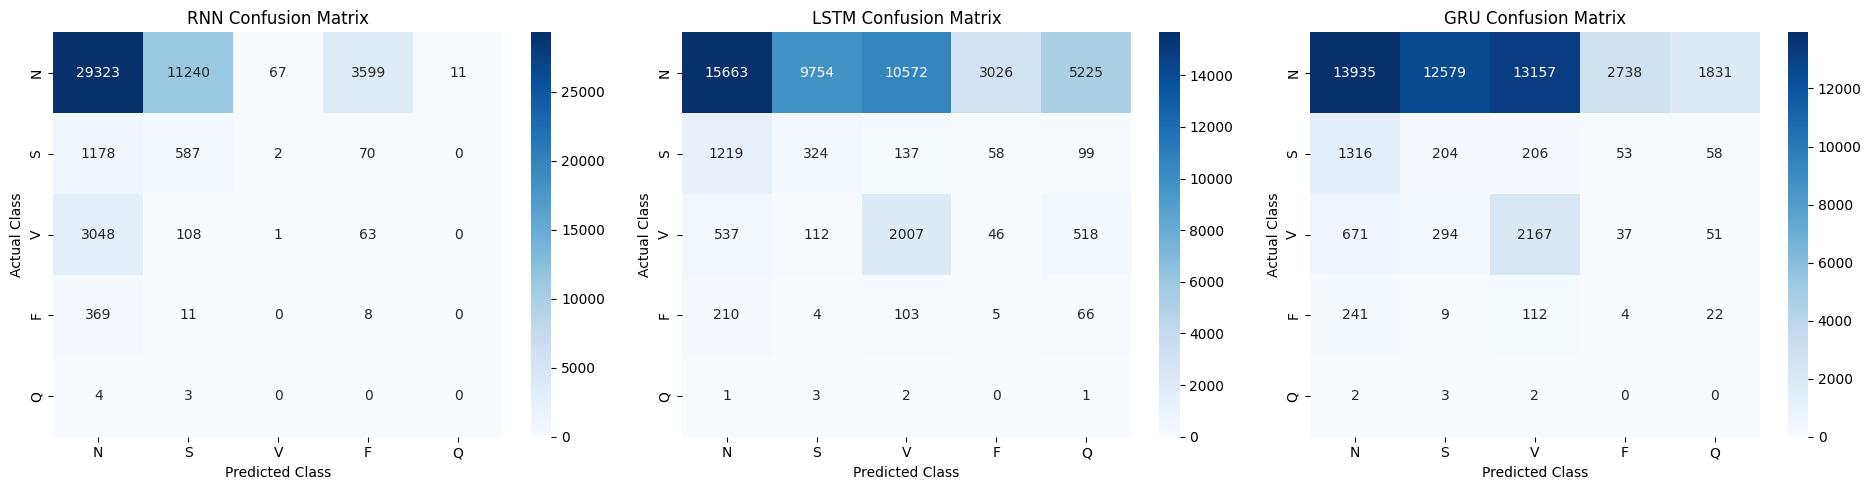

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3, 4])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=ax
    )
    ax.set_title(name + " Confusion Matrix")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

## 15. Compare model performance

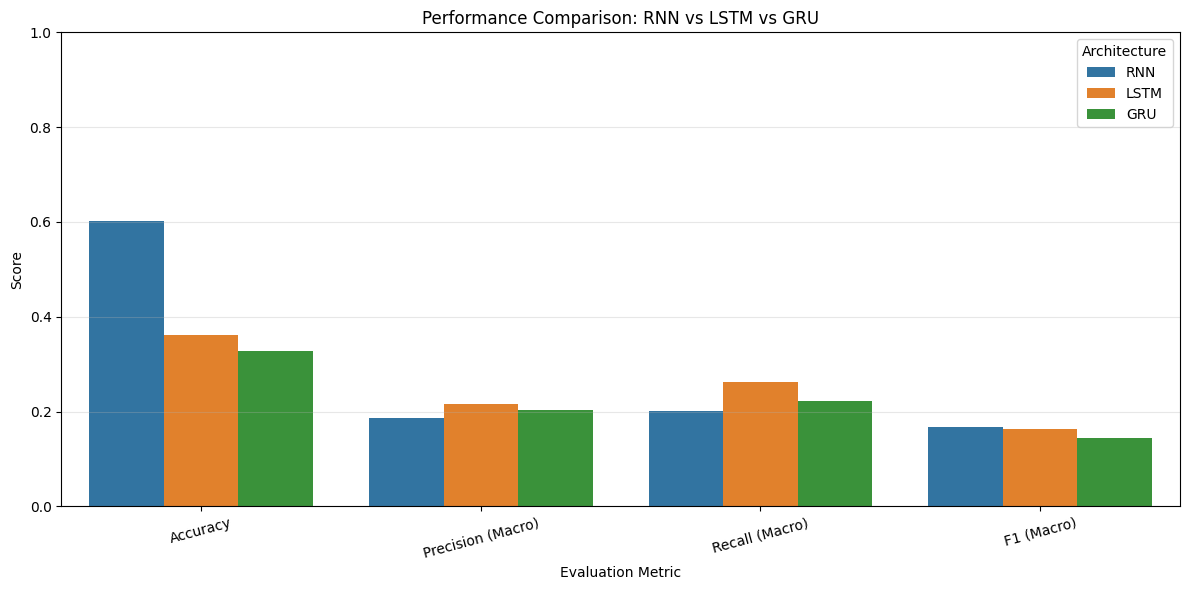


BEST MODEL BASED ON MACRO F1
Model                        RNN
Accuracy                0.602089
Precision (Macro)       0.185995
Recall (Macro)          0.200658
F1 (Macro)              0.167991
Precision (Weighted)    0.772342
Recall (Weighted)       0.602089
F1 (Weighted)            0.67121


In [15]:
metrics = ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1 (Macro)"]

plot_data = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))
sns.barplot(data=plot_data, x="Metric", y="Score", hue="Model")
plt.title("Performance Comparison: RNN vs LSTM vs GRU")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Architecture")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

best_model = results_df.loc[results_df["F1 (Macro)"].idxmax()]
print("\nBEST MODEL BASED ON MACRO F1")
print(best_model.to_string())

## 16. Save trained models and results

In [16]:
OUTPUT_DIR = "/content/Arrhythmia_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for name, model in models.items():
    model.save(os.path.join(OUTPUT_DIR, f"{name}_Arrhythmia_Model.keras"))
    print(name, "model saved!")

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "Model_Comparison.csv"),
    index=False
)

prediction_df = pd.DataFrame({"Actual": y_test})
for name, pred in predictions.items():
    prediction_df[name + "_Prediction"] = pred

prediction_df.to_csv(
    os.path.join(OUTPUT_DIR, "Test_Predictions.csv"),
    index=False
)

print("All results saved in:", OUTPUT_DIR)

import shutil
shutil.make_archive("/content/Arrhythmia_Results", "zip", OUTPUT_DIR)

from google.colab import files
files.download("/content/Arrhythmia_Results.zip")

RNN model saved!
LSTM model saved!
GRU model saved!
All results saved in: /content/Arrhythmia_Results


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>